In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Import preprocessing tools
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Import tools to build a preprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Import Linear Regression model
from sklearn.linear_model import LinearRegression

# Import evaluation metrics
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [2]:
# Load the used-car dataset
df = pd.read_csv("car details v4 3.csv")
# Display the first five data
df.head()

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0


In [3]:
# Display the last five rows
df.tail()
# Display the dataset dimensions
print("Number of rows and columns:", df.shape)
# Display all column names
print(df.columns)
# Display column names, data types, and non-null counts
df.info()
# Display statistics for numerical columns
df.describe()

Number of rows and columns: (2059, 20)
Index(['Make', 'Model', 'Price', 'Year', 'Kilometer', 'Fuel Type',
       'Transmission', 'Location', 'Color', 'Owner', 'Seller Type', 'Engine',
       'Max Power', 'Max Torque', 'Drivetrain', 'Length', 'Width', 'Height',
       'Seating Capacity', 'Fuel Tank Capacity'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                2059 non-null   object 
 1   Model               2059 non-null   object 
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   Kilometer           2059 non-null   int64  
 5   Fuel Type           2059 non-null   object 
 6   Transmission        2059 non-null   object 
 7   Location            2059 non-null   object 
 8   Color               2059 non-null   object 
 9   Owner           

,Price,Year,Kilometer,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
count,2.059000e+03,2059.000000,2.059000e+03,1995.000000,1995.000000,1995.000000,1995.000000,1946.000000
mean,1.702992e+06,2016.425449,5.422471e+04,4280.860652,1767.991980,1591.735338,5.306266,52.002210
std,2.419881e+06,3.363564,5.736172e+04,442.458507,135.265825,136.073956,0.822170,15.110198
min,4.900000e+04,1988.000000,0.000000e+00,3099.000000,1475.000000,1165.000000,2.000000,15.000000
25%,4.849990e+05,2014.000000,2.900000e+04,3985.000000,1695.000000,1485.000000,5.000000,41.250000
50%,8.250000e+05,2017.000000,5.000000e+04,4370.000000,1770.000000,1545.000000,5.000000,50.000000
75%,1.925000e+06,2019.000000,7.200000e+04,4629.000000,1831.500000,1675.000000,5.000000,60.000000
max,3.500000e+07,2022.000000,2.000000e+06,5569.000000,2220.000000,1995.000000,8.000000,105.000000


In [4]:
# Count missing values in each column
print(df.isnull().sum())

Make                    0
Model                   0
Price                   0
Year                    0
Kilometer               0
Fuel Type               0
Transmission            0
Location                0
Color                   0
Owner                   0
Seller Type             0
Engine                 80
Max Power              80
Max Torque             80
Drivetrain            136
Length                 64
Width                  64
Height                 64
Seating Capacity       64
Fuel Tank Capacity    113
dtype: int64


In [5]:
# Calculate the total number of missing values
print("Total missing values:", df.isnull().sum().sum())
# Calculate missing values as a percentage of each column
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Display the result
print(missing_percentage)

Total missing values: 745
Make                  0.000000
Model                 0.000000
Price                 0.000000
Year                  0.000000
Kilometer             0.000000
Fuel Type             0.000000
Transmission          0.000000
Location              0.000000
Color                 0.000000
Owner                 0.000000
Seller Type           0.000000
Engine                3.885381
Max Power             3.885381
Max Torque            3.885381
Drivetrain            6.605148
Length                3.108305
Width                 3.108305
Height                3.108305
Seating Capacity      3.108305
Fuel Tank Capacity    5.488101
dtype: float64


In [6]:
# Count duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


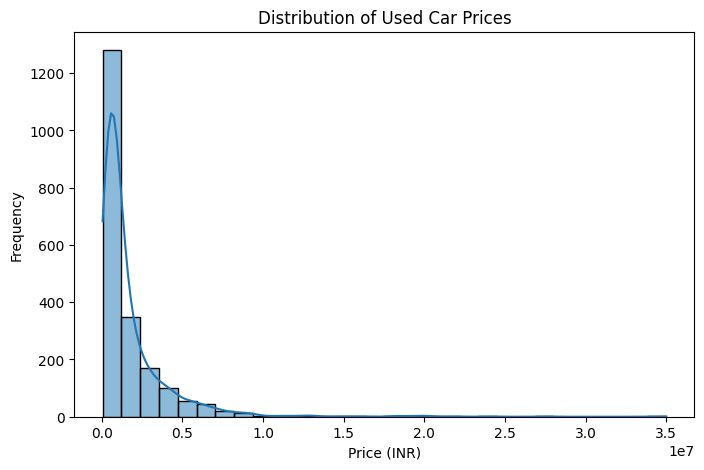

In [7]:
# Plot the distribution of car prices
plt.figure(figsize=(8, 5))

# Create a histogram
sns.histplot(data=df, x="Price", bins=30, kde=True)

# Add a title and axis labels
plt.title("Distribution of Used Car Prices")
plt.xlabel("Price (INR)")
plt.ylabel("Frequency")

# Display the graph
plt.show()

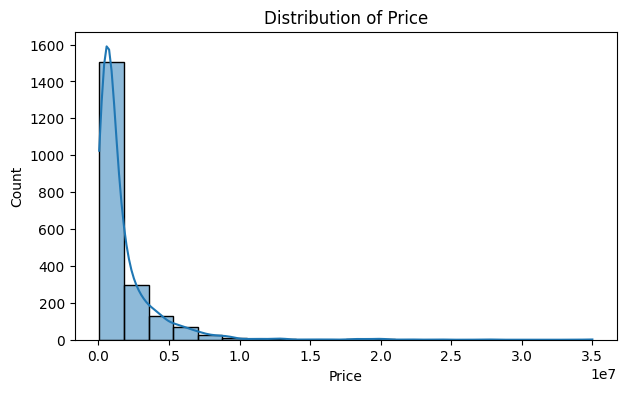

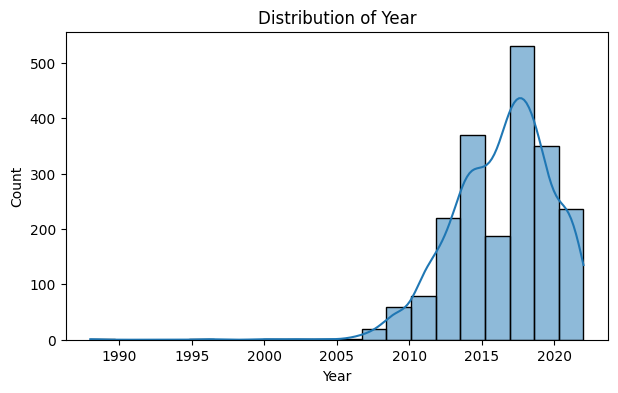

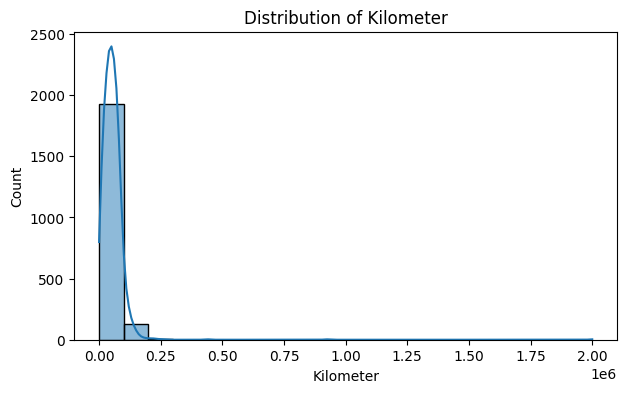

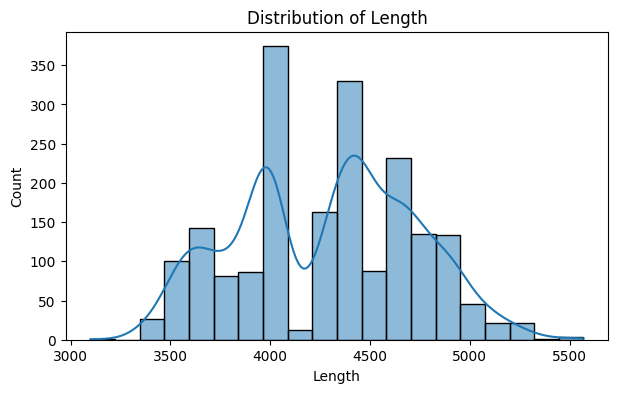

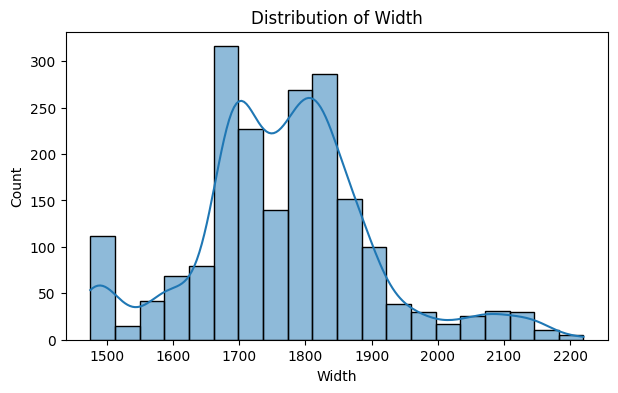

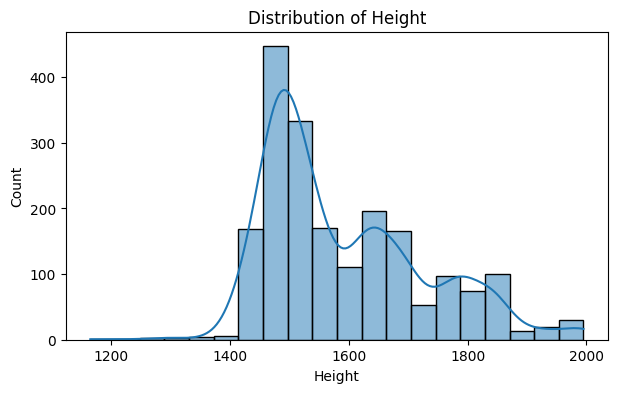

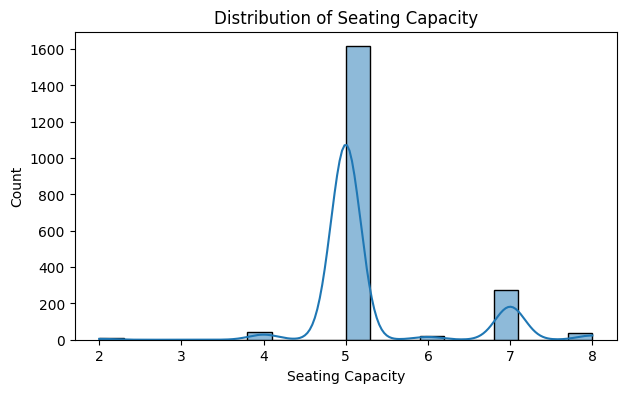

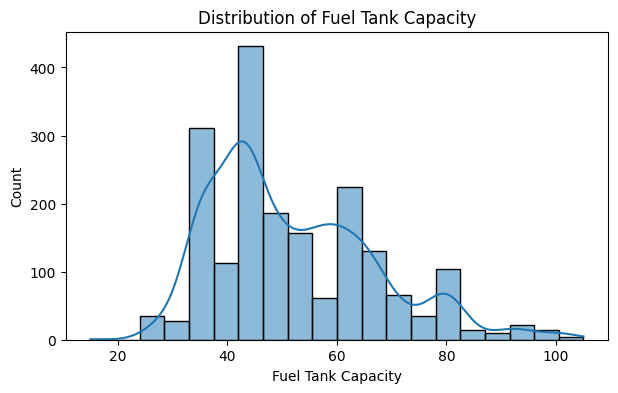

In [8]:
# Select numerical columns
numeric_columns = df.select_dtypes(include="number").columns

# Plot a histogram for each numerical column
for column in numeric_columns:

    # Create a new figure
    plt.figure(figsize=(7, 4))

    # Plot the histogram
    sns.histplot(data=df, x=column, bins=20, kde=True)

    # Add the title
    plt.title("Distribution of " + column)

    # Display the graph
    plt.show()

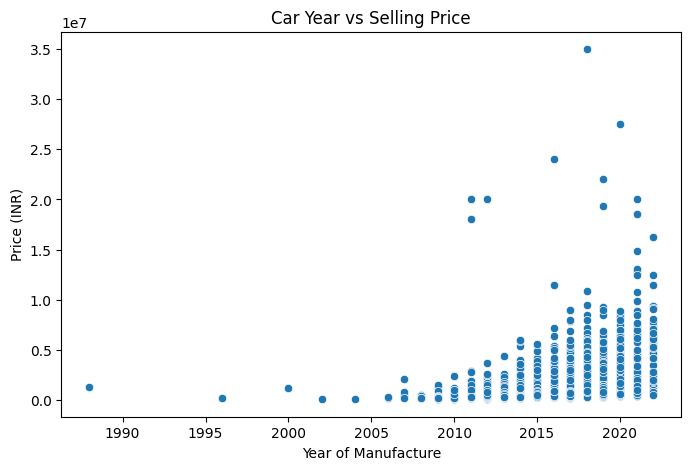

In [9]:
# Create a scatter plot to examine the relationship between year and price
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Year", y="Price")

# Add the title and axis labels
plt.title("Car Year vs Selling Price")
plt.xlabel("Year of Manufacture")
plt.ylabel("Price (INR)")

# Display the graph
plt.show()

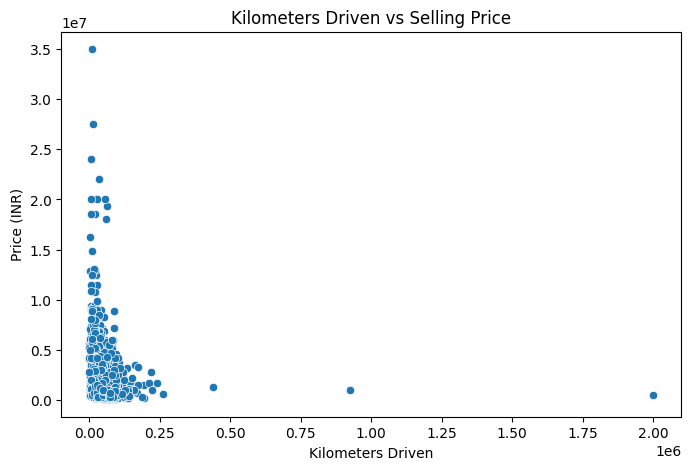

In [10]:
# Create a scatter plot
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Kilometer", y="Price")

# Add the title and labels
plt.title("Kilometers Driven vs Selling Price")
plt.xlabel("Kilometers Driven")
plt.ylabel("Price (INR)")

# Display the graph
plt.show()


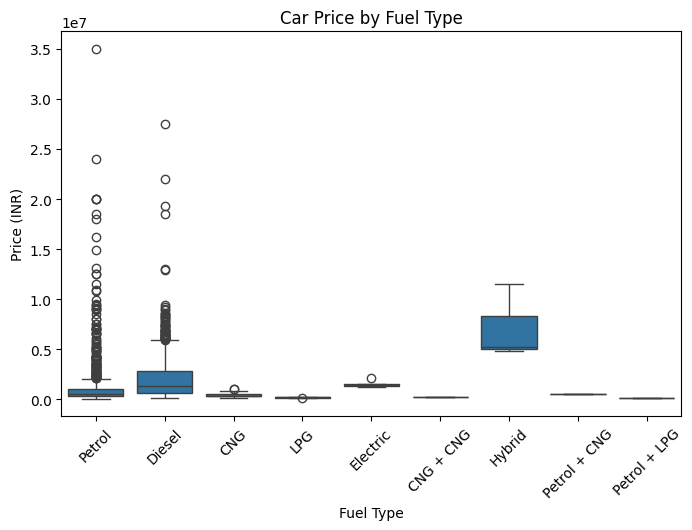

In [12]:
# Compare car prices across fuel types
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Fuel Type", y="Price")

# Add the title and labels
plt.title("Car Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Price (INR)")

# Rotate the category labels for readability
plt.xticks(rotation=45)

# Display the graph
plt.show()

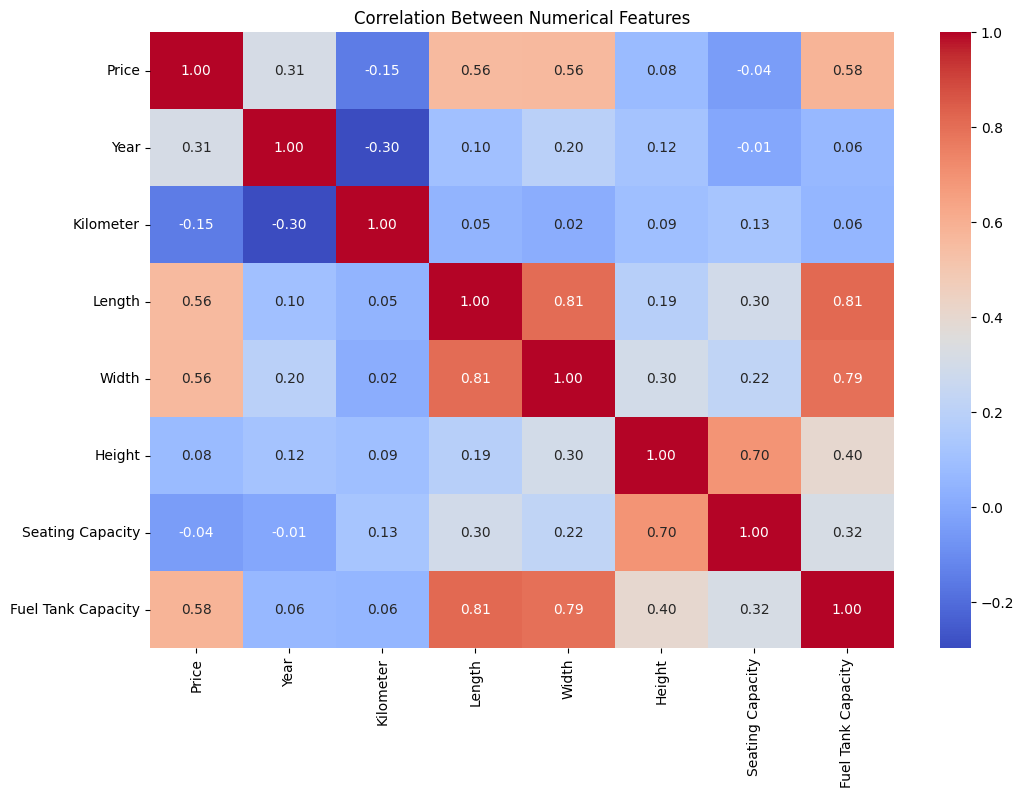

In [13]:
# Select numerical columns
numeric_data = df.select_dtypes(include="number")

# Calculate the correlation matrix
correlation = numeric_data.corr()

# Create a heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

# Add a title
plt.title("Correlation Between Numerical Features")

# Display the graph
plt.show()

Data Preprocessing

In [14]:
# Create a copy of the original dataset
df = df.copy()

# Convert Engine capacity into a numerical value
df["Engine"] = pd.to_numeric(
    df["Engine"].astype(str).str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

# Extract the numerical value of maximum power
df["Max Power"] = pd.to_numeric(
    df["Max Power"].astype(str).str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

# Extract the numerical value of maximum torque
df["Max Torque"] = pd.to_numeric(
    df["Max Torque"].astype(str).str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

# Display the converted columns
print(df[["Engine", "Max Power", "Max Torque"]].head())

   Engine  Max Power  Max Torque
0  1198.0       87.0    109.0000
1  1248.0       74.0    190.0000
2  1197.0       79.0    112.7619
3  1197.0       82.0    113.0000
4  2393.0      148.0    343.0000


In [15]:
# Select the input features
X = df.drop("Price", axis=1)

# Select the target variable
y = df["Price"]

# Display the input features
print("Input features:")
print(X.head())

# Display the target variable
print("\nTarget variable:")
print(y.head())

Input features:
            Make                            Model  Year  Kilometer Fuel Type  \
0          Honda              Amaze 1.2 VX i-VTEC  2017      87150    Petrol   
1  Maruti Suzuki                  Swift DZire VDI  2014      75000    Diesel   
2        Hyundai             i10 Magna 1.2 Kappa2  2011      67000    Petrol   
3         Toyota                         Glanza G  2019      37500    Petrol   
4         Toyota  Innova 2.4 VX 7 STR [2016-2020]  2018      69000    Diesel   

  Transmission   Location   Color   Owner Seller Type  Engine  Max Power  \
0       Manual       Pune    Grey   First   Corporate  1198.0       87.0   
1       Manual   Ludhiana   White  Second  Individual  1248.0       74.0   
2       Manual    Lucknow  Maroon   First  Individual  1197.0       79.0   
3       Manual  Mangalore     Red   First  Individual  1197.0       82.0   
4       Manual     Mumbai    Grey   First  Individual  2393.0      148.0   

   Max Torque Drivetrain  Length   Width  Heig

In [16]:
# Identify numerical columns
numeric_features = X.select_dtypes(include="number").columns

# Identify categorical columns
categorical_features = X.select_dtypes(exclude="number").columns

# Display numerical columns
print("Numerical columns:")
print(list(numeric_features))

# Display categorical columns
print("\nCategorical columns:")
print(list(categorical_features))

Numerical columns:
['Year', 'Kilometer', 'Engine', 'Max Power', 'Max Torque', 'Length', 'Width', 'Height', 'Seating Capacity', 'Fuel Tank Capacity']

Categorical columns:
['Make', 'Model', 'Fuel Type', 'Transmission', 'Location', 'Color', 'Owner', 'Seller Type', 'Drivetrain']


In [17]:
# Divide the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Display the sizes of the datasets
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1647, 19)
Testing data: (412, 19)


In [18]:
# Create a preprocessing pipeline for numerical features
numeric_pipeline = Pipeline(steps=[

    # Fill missing numerical values with the median
    ("imputer", SimpleImputer(strategy="median")),

    # Scale numerical features
    ("scaler", StandardScaler())
])

# Create a preprocessing pipeline for categorical features
categorical_pipeline = Pipeline(steps=[

    # Fill missing categorical values with the most frequent value
    ("imputer", SimpleImputer(strategy="most_frequent")),

    # Convert categorical values into numerical columns
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each type of column
preprocessor = ColumnTransformer(transformers=[

    # Process numerical columns
    ("num", numeric_pipeline, numeric_features),

    # Process categorical columns
    ("cat", categorical_pipeline, categorical_features)
])

# Display a message
print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


Model Development Using Linear Regression

In [19]:
# Create a pipeline containing preprocessing and Linear Regression
model = Pipeline(steps=[

    # Preprocess the input features
    ("preprocessor", preprocessor),

    # Train the Linear Regression model
    ("regressor", LinearRegression())
])

# Display the model
print(model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Year', 'Kilometer', 'Engine', 'Max Power', 'Max Torque', 'Length',
       'Width', 'Height', 'Seating Capacity', 'Fuel Tank Capacity'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                         

In [20]:
# Train the model using the training dataset
model.fit(X_train, y_train)

# Display a confirmation message
print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [21]:
# Predict prices for the test dataset
y_pred = model.predict(X_test)

# Display the first ten predicted prices
print("Predicted prices:")
print(y_pred[:10])

Predicted prices:
[ 1.02204786e+07  8.54934277e+05 -3.01827776e+06  1.30117328e+06
  6.77543691e+05  5.59825391e+02 -1.74944192e+06 -1.01234338e+06
  1.61265454e+07  2.00832769e+06]


In [22]:
# Calculate Mean Squared Error
mse = mean_squared_error(y_test, y_pred)

# Display the result
print("Mean Squared Error:", mse)

Mean Squared Error: 17982335278074.84


In [23]:
# Calculate Root Mean Squared Error
rmse = np.sqrt(mse)

# Display the result
print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 4240558.368667367


In [24]:
# Calculate Mean Absolute Error
mae = mean_absolute_error(y_test, y_pred)

# Display the result
print("Mean Absolute Error:", mae)

Mean Absolute Error: 1830847.4930129508


In [25]:
# Calculate the R-2 score
r2 = r2_score(y_test, y_pred)

# Display the result
print("R-squared Score:", r2)

R-squared Score: -1.5739491751388286


In [26]:
# Create a DataFrame containing actual and predicted prices
results = pd.DataFrame({

    # Actual selling prices
    "Actual Price": y_test.values,

    # Predicted selling prices
    "Predicted Price": y_pred
})

# Calculate the difference between actual and predicted prices
results["Difference"] = (
    results["Actual Price"] - results["Predicted Price"]
)

# Display the first ten results
print(results.head(10))

   Actual Price  Predicted Price    Difference
0       4800000     1.022048e+07 -5.420479e+06
1        825000     8.549343e+05 -2.993428e+04
2        695000    -3.018278e+06  3.713278e+06
3        950000     1.301173e+06 -3.511733e+05
4        819999     6.775437e+05  1.424553e+05
5        310000     5.598254e+02  3.094402e+05
6       1000000    -1.749442e+06  2.749442e+06
7       1998999    -1.012343e+06  3.011342e+06
8        850000     1.612655e+07 -1.527655e+07
9       3950000     2.008328e+06  1.941672e+06


In [27]:
# Create a DataFrame containing actual and predicted prices
results = pd.DataFrame({

    # Actual selling prices
    "Actual Price": y_test.values,

    # Predicted selling prices
    "Predicted Price": y_pred
})

# Calculate the difference between actual and predicted prices
results["Difference"] = (
    results["Actual Price"] - results["Predicted Price"]
)

# Display the first ten results
print(results.head(10))

   Actual Price  Predicted Price    Difference
0       4800000     1.022048e+07 -5.420479e+06
1        825000     8.549343e+05 -2.993428e+04
2        695000    -3.018278e+06  3.713278e+06
3        950000     1.301173e+06 -3.511733e+05
4        819999     6.775437e+05  1.424553e+05
5        310000     5.598254e+02  3.094402e+05
6       1000000    -1.749442e+06  2.749442e+06
7       1998999    -1.012343e+06  3.011342e+06
8        850000     1.612655e+07 -1.527655e+07
9       3950000     2.008328e+06  1.941672e+06


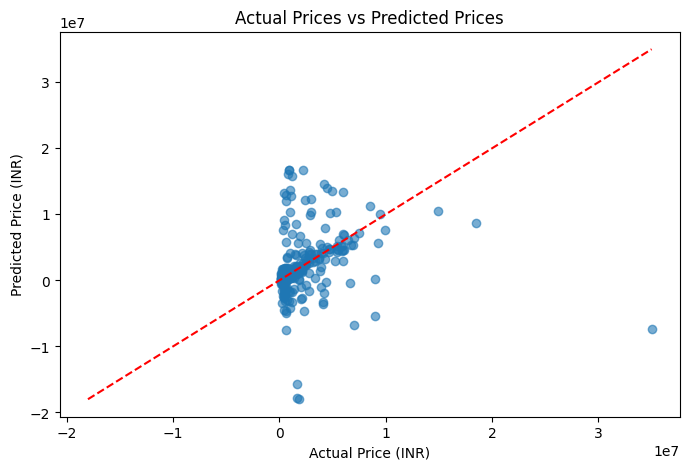

In [28]:
# Create a scatter plot
plt.figure(figsize=(8, 5))

# Plot actual prices against predicted prices
plt.scatter(y_test, y_pred, alpha=0.6)

# Add a reference line representing perfect predictions
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--"
)

# Add the title and axis labels
plt.title("Actual Prices vs Predicted Prices")
plt.xlabel("Actual Price (INR)")
plt.ylabel("Predicted Price (INR)")

# Display the graph
plt.show()

In [30]:
# Display all model evaluation metrics
print("Model Evaluation Results")
print("------------------------")

print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("Mean Absolute Error:", mae)
print("R-squared Score:", r2)

Model Evaluation Results
------------------------
Mean Squared Error: 17982335278074.84
Root Mean Squared Error: 4240558.368667367
Mean Absolute Error: 1830847.4930129508
R-squared Score: -1.5739491751388286


In [29]:
# Interpret the R-squared score
if r2 > 0.8:
    print("The model explains a large proportion of price variation.")
elif r2 > 0.5:
    print("The model explains a moderate proportion of price variation.")
elif r2 >= 0:
    print("The model explains a limited proportion of price variation.")
else:
    print("The model performs worse than a mean-price baseline.")

The model performs worse than a mean-price baseline.


In [31]:
# Display the final summary of the Linear Regression model

print("USED CAR PRICE PREDICTION")
print("=========================")

# Display the dataset size after duplicate removal
print("Dataset size:", df.shape)

# Display the number of training records
print("Training records:", len(X_train))

# Display the number of testing records
print("Testing records:", len(X_test))

# Display the evaluation metrics
print("\nMODEL PERFORMANCE")
print("-----------------")
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("MAE:", round(mae, 2))
print("R-squared:", round(r2, 4))

# Display the first five actual and predicted prices
print("\nACTUAL VS PREDICTED PRICES")
print("--------------------------")
print(results.head())

USED CAR PRICE PREDICTION
Dataset size: (2059, 20)
Training records: 1647
Testing records: 412

MODEL PERFORMANCE
-----------------
MSE: 17982335278074.84
RMSE: 4240558.37
MAE: 1830847.49
R-squared: -1.5739

ACTUAL VS PREDICTED PRICES
--------------------------
   Actual Price  Predicted Price    Difference
0       4800000     1.022048e+07 -5.420479e+06
1        825000     8.549343e+05 -2.993428e+04
2        695000    -3.018278e+06  3.713278e+06
3        950000     1.301173e+06 -3.511733e+05
4        819999     6.775437e+05  1.424553e+05
